# PCA, NMF and anomaly detection — Code-Along Template

**Type into this notebook during class.** The explanation is here; the code is not.

| | |
|---|---|
| **Follow along** | Write the code in each `# TODO` cell. The hint names the functions and arguments. |
| **If you fall behind** | Do not copy frantically. Skip to the next **CHECKPOINT**, run it, rejoin. |
| **If a cell errors** | Later cells depend on it and will fail too. Run the next CHECKPOINT rather than debugging under time pressure. |
| **After class** | The worked version is `D014_01_PCA_Fundamentals.ipynb`. Compare, do not copy. |

Cells that are already filled in are deliberate — imports and quick glances at the
data cost class time and teach nothing.

# C3: PCA Transformation and Dimensionality Reduction

## 1. Introduction to PCA

**Principal Component Analysis (PCA)** is a fundamental technique in unsupervised learning. It performs two key tasks:
1.  **Decorrelation**: It rotates the data samples to be aligned with the axes of maximum variance.
2.  **Dimensionality Reduction**: It compresses the data by keeping only the most important axes (Principal Components).

### Conceptual View
Imagine fitting an arrow through the data cloud where it spreads out the most. That's the first Principal Component (PC1). The second one (PC2) is perpendicular to it.

![PCA Illustration](https://upload.wikimedia.org/wikipedia/commons/f/f5/GaussianScatterPCA.svg)
*(Source: Wikimedia Commons - PCA finding the principal axes of variance in data)*

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)

In [ ]:
# ═══ CHECKPOINT — "Decorrelation Example" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np
plt.rcParams['figure.figsize'] = (10, 6)

print("Checkpoint restored. Ready for: Decorrelation Example")

### Decorrelation Example
Let's look at the `seeds.csv` dataset. Some features like 'area' and 'perimeter' are highly correlated.

In [ ]:
# TODO: compute `columns`, `df_seeds`, `features`
# Name your result: columns, df_seeds, features, X_seeds

In [ ]:
# TODO: compute `pca`, `X_transformed`
# Name your result: pca, X_transformed

## 2. Intrinsic Dimension

The **Intrinsic Dimension** is the number of features needed to approximate the dataset effectively. We find this by looking at the **Explained Variance** of each component.

Let's use the `fish_measurement.csv` dataset, which has multiple dimensions.

In [ ]:
# TODO: compute `df_fish`, `X_fish`, `scaler`
# Name your result: df_fish, X_fish, scaler, X_fish_scaled

**Interpretation**: If the first 2 components describe 90% of the variance, the intrinsic dimension is likely 2.

## 3. Dimensionality Reduction (LCD Digits)

One of the coolest applications is reducing image data. We have `lcd_digits.csv`, which represents 13x8 pixel images of digits (flattened to ~100 features).

Can we compress this to just 2 dimensions and still distinguish the numbers?

Original Dimensions: 104
Reduced Dimensions: 2


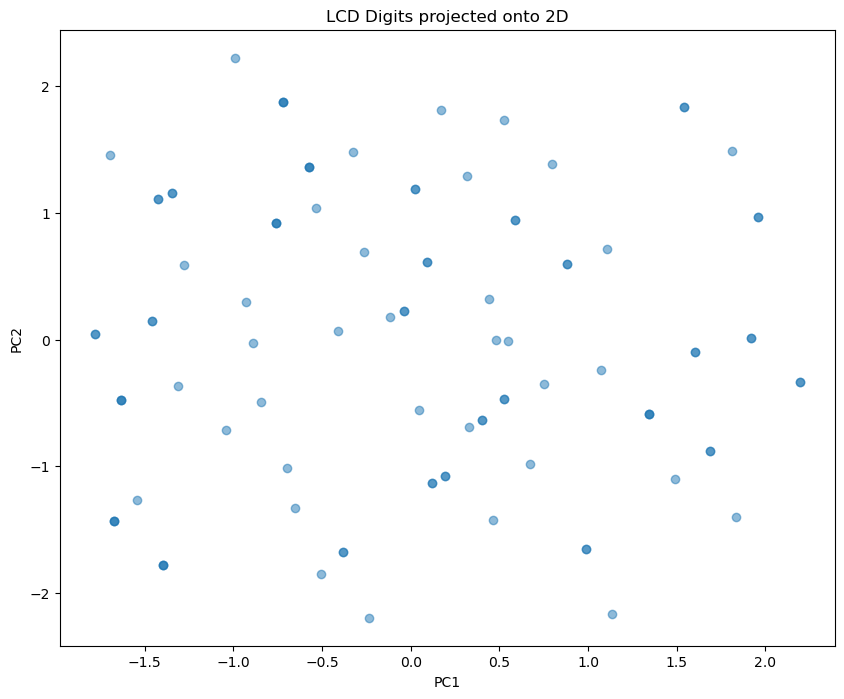

In [7]:
# Load Digits
df_digits = pd.read_csv('../../00-data/lcd_digits.csv', header=None,skiprows=[0])
X_digits = df_digits.values

print(f"Original Dimensions: {X_digits.shape[1]}")

# Reduce to 2 Dimensions
pca_digits = PCA(n_components=2)
X_reduced = pca_digits.fit_transform(X_digits)

print(f"Reduced Dimensions: {X_reduced.shape[1]}")

# Visualize
plt.figure(figsize=(10, 8))
# We don't have labels in this csv, so we just plot the scatter to see the structure
plt.scatter(X_reduced[:, 0], X_reduced[:, 1], alpha=0.5)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('LCD Digits projected onto 2D')
plt.show()

In [ ]:
# ═══ CHECKPOINT — "Comparison: PCA vs. t-SNE" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np
plt.rcParams['figure.figsize'] = (10, 6)
columns = ['area', 'perimeter', 'compactness', 'length', 'width', 'asymmetry', 'groove', 'species']
df_seeds = pd.read_csv('../../00-data/seeds.csv', header=None, names=columns)
features = ['area', 'perimeter']
X_seeds = df_seeds[features].values
pca = PCA(n_components=2)
pca.fit(X_seeds)
X_transformed = pca.transform(X_seeds)
df_fish = pd.read_csv('../../00-data/fish_measurement.csv', header=None)
X_fish = df_fish.select_dtypes(include=[np.number]).values
scaler = StandardScaler()
X_fish_scaled = scaler.fit_transform(X_fish)
pca_fish = PCA()
pca_fish.fit(X_fish_scaled)
features = range(pca_fish.n_components_)
df_digits = pd.read_csv('../../00-data/lcd_digits.csv', header=None, skiprows=[0])
X_digits = df_digits.values
pca_digits = PCA(n_components=2)
X_reduced = pca_digits.fit_transform(X_digits)

print("Checkpoint restored. Ready for: Comparison: PCA vs. t-SNE")

## 4. Comparison: PCA vs. t-SNE

- **PCA** is linear. It's fast and simplifies data globally.
- **t-SNE** is non-linear. It's great for visualizing clusters but preserves local neighborhoods.

![PCA vs t-SNE comparison](https://upload.wikimedia.org/wikipedia/commons/1/1a/Uniform_t-SNE_vs_PCA_on_MNIST.png)
*(Source: Wikimedia Commons - Visual comparison showing how PCA smears classes while t-SNE separates them distinctly)*

## 5. Exercises: Wine Dataset

Your turn! Use the `wine.csv` dataset, which contains chemical analysis of wines grown in the same region in Italy but derived from three different cultivars.

**Goal**: Reduce the 13 chemical features to 2 and visualize the Cultivars.

1.  **Load** `datasets/wine.csv`.
2.  **Separate** labels (`class_label`) and features (`alcohol` to `proline`).
3.  **Scale** the features.
4.  **PCA**: Fit and transform to 2 components.
5.  **Visualize**: Scatter plot PC1 vs PC2, colored by `class_label`.